# Practical 5 – Tarrataca's Quantum Production System with the 3-Puzzle

**Aim:** Implement Tarrataca's quantum production system with the 3-puzzle problem.

**Outcome:** Write a Python program using Tarrataca's quantum production system for the 3-puzzle problem.

**Theory**

A **production system** has (1) a set of states, (2) production rules *if condition then action* and (3) a control
strategy that chooses which rule to fire. Classical search of all rule sequences of depth *d* with branching factor *b*
takes O(bᵈ) steps.

**Tarrataca & Wichert** proposed a *quantum production system*: the choice of rule at every step is stored in a
quantum register, all bᵈ rule sequences are put in **superposition**, an **oracle** marks the sequences that take the
initial state to the goal state, and **Grover's algorithm** amplifies them, giving a quadratic speed-up O(√(bᵈ)).

**The 3-puzzle:** a 2×2 board with tiles 1, 2, 3 and a blank (0). A rule moves a tile next to the blank into the blank.
On a 2×2 board the blank always has exactly **2 neighbours**, so b = 2 and each step needs **1 qubit**
(0 = first legal move, 1 = second legal move). A search of depth *d* uses *d* qubits.

**Steps**
1. Define states, production rules and goal (classical part)
2. Build the oracle that marks rule sequences reaching the goal
3. Put all 2ᵈ sequences in superposition (Hadamards), run Grover iterations (oracle + diffuser)
4. Measure, decode the rule sequence and replay it on the puzzle

In [1]:
# Run this cell first in Google Colab (installs Qiskit + simulator)
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jadha\AppData\Local\Temp\claude\efb368ed25e968d0\a89940ab-0696-4fca-91e1-025ecd80d2c1\scratchpad\qenv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
from math import floor, pi, sqrt, asin
from itertools import product
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# ---- 1. Production system for the 3-puzzle -------------------------------
# board index layout:  0 1
#                      2 3
NEIGHBOURS = {0: [1, 2], 1: [0, 3], 2: [0, 3], 3: [1, 2]}
GOAL = (1, 2, 3, 0)

def show(state):
    s = [str(t) if t else " " for t in state]
    return f"+---+---+\n| {s[0]} | {s[1]} |\n+---+---+\n| {s[2]} | {s[3]} |\n+---+---+"

def legal_rules(state):
    """Production rules applicable in a state: 'move tile at position p into the blank'."""
    blank = state.index(0)
    return [(p, blank) for p in NEIGHBOURS[blank]]

def apply_rule(state, rule):
    src, dst = rule
    s = list(state)
    s[dst], s[src] = s[src], 0
    return tuple(s)

def run_sequence(state, bits):
    """Each bit chooses which of the 2 applicable rules fires at that step."""
    path = [state]
    for b in bits:
        state = apply_rule(state, legal_rules(state)[b])
        path.append(state)
    return path

INITIAL = (0, 1, 3, 2)
print("Initial state:\n" + show(INITIAL))
print("Goal state:\n" + show(GOAL))

Initial state:
+---+---+
|   | 1 |
+---+---+
| 3 | 2 |
+---+---+
Goal state:
+---+---+
| 1 | 2 |
+---+---+
| 3 |   |
+---+---+


In [3]:
# ---- 2. Which rule sequences of depth d reach the goal? (oracle truth table)
DEPTH = 4
solutions = [bits for bits in product([0, 1], repeat=DEPTH)
             if run_sequence(INITIAL, bits)[-1] == GOAL]
print(f"Search space: 2^{DEPTH} = {2**DEPTH} rule sequences")
print("Sequences that reach the goal:", ["".join(map(str, s)) for s in solutions])
assert solutions, "No solution at this depth - change INITIAL or DEPTH"

Search space: 2^4 = 16 rule sequences
Sequences that reach the goal: ['0001', '0101', '0111', '1001']


Grover iterations: 1


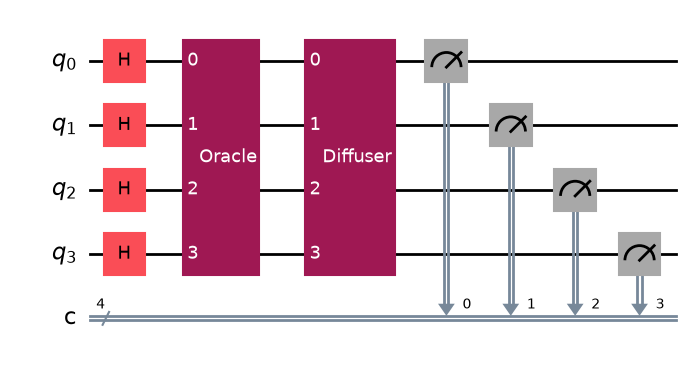

In [4]:
# ---- 3. Quantum part: oracle + Grover diffuser ---------------------------
def oracle(n, marked):
    """Phase oracle: flips the sign of every marked rule sequence.
    Qubit i holds the rule choice of step i."""
    qc = QuantumCircuit(n, name="Oracle")
    for bits in marked:
        zeros = [i for i, b in enumerate(bits) if b == 0]
        if zeros: qc.x(zeros)
        qc.h(n - 1); qc.mcx(list(range(n - 1)), n - 1); qc.h(n - 1)   # multi-controlled Z
        if zeros: qc.x(zeros)
    return qc

def diffuser(n):
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n)); qc.x(range(n))
    qc.h(n - 1); qc.mcx(list(range(n - 1)), n - 1); qc.h(n - 1)
    qc.x(range(n)); qc.h(range(n))
    return qc

N, M = 2 ** DEPTH, len(solutions)
iterations = max(1, floor(pi / (4 * asin(sqrt(M / N)))))
print("Grover iterations:", iterations)

qps = QuantumCircuit(DEPTH, DEPTH)
qps.h(range(DEPTH))                      # superposition of all rule sequences
for _ in range(iterations):
    qps.append(oracle(DEPTH, solutions).to_gate(), range(DEPTH))
    qps.append(diffuser(DEPTH).to_gate(), range(DEPTH))
qps.measure(range(DEPTH), range(DEPTH))
qps.draw('mpl')

Measured rule sequences (step1..stepd): {'0001': 526, '0111': 519, '1001': 513, '0101': 490}
Probability of measuring a solution: 1.000  (random guess would be 0.250)


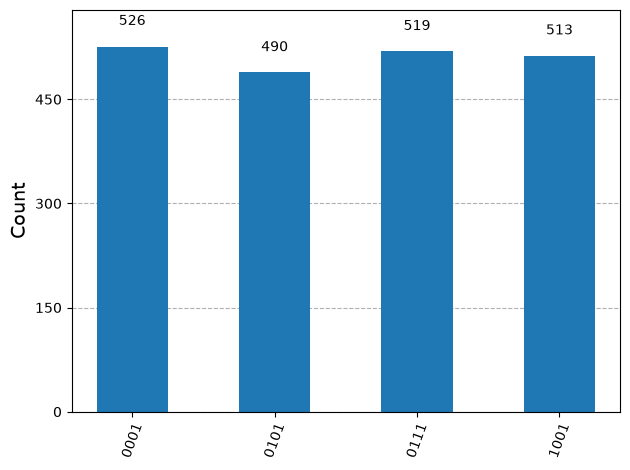

In [5]:
sim = AerSimulator()
counts = sim.run(transpile(qps, sim), shots=2048).result().get_counts()
# Qiskit prints qubit 0 on the right, so reverse to get step order 1..d
counts_steps = {k[::-1]: v for k, v in counts.items()}
print("Measured rule sequences (step1..stepd):", dict(sorted(counts_steps.items(), key=lambda kv: -kv[1])))
success = sum(v for k, v in counts_steps.items() if tuple(map(int, k)) in solutions) / 2048
print(f"Probability of measuring a solution: {success:.3f}  (random guess would be {M/N:.3f})")
plot_histogram(counts_steps)

In [6]:
# ---- 4. Decode the most likely sequence and replay it --------------------
# among the measured solutions pick the one that reaches the goal earliest (shortest path)
found = [k for k in counts_steps if tuple(map(int, k)) in solutions]
best = min(found, key=lambda k: run_sequence(INITIAL, tuple(map(int, k))).index(GOAL))
bits = tuple(map(int, best))
path = run_sequence(INITIAL, bits)
print("Best rule sequence:", best)
for step, (b, state) in enumerate(zip((None,) + bits, path)):
    title = "Initial" if step == 0 else f"Step {step}: fire rule #{b} -> move tile {path[step-1][legal_rules(path[step-1])[b][0]]}"
    print(title); print(show(state))
    if state == GOAL:          # production system halts when the goal is reached
        print(f"Goal reached after {step} moves")
        break

Best rule sequence: 0101
Initial
+---+---+
|   | 1 |
+---+---+
| 3 | 2 |
+---+---+
Step 1: fire rule #0 -> move tile 1
+---+---+
| 1 |   |
+---+---+
| 3 | 2 |
+---+---+
Step 2: fire rule #1 -> move tile 2
+---+---+
| 1 | 2 |
+---+---+
| 3 |   |
+---+---+
Goal reached after 2 moves


**Conclusion:** The 3-puzzle was modelled as a production system (states, rules, goal). Following Tarrataca's quantum
production system, all rule sequences of depth 4 were placed in superposition, an oracle marked the sequences reaching
the goal and Grover's algorithm amplified them, so a measurement returns a valid solution path with (near) 100 %
probability using only one oracle call instead of checking all 16 sequences classically.